In [1]:
# เฉลย: ย้ายไปทำงานที่โฟลเดอร์ labs/ (ที่มี data/ และ mlia.py)
import os, sys
if os.path.basename(os.getcwd()) == "solution":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

# Lab 3 · อธิบาย model ด้วย SHAP (≈ 50 นาที)

แพทย์จะไม่เชื่อ model ที่บอกแค่ว่า "เสี่ยง 72%" — เขาอยากรู้ว่า **เสี่ยงเพราะอะไร**
และผู้ดูแลระบบอยากรู้ว่า model **เรียนรู้อะไร** มา สมเหตุสมผลทางการแพทย์ไหม

**SHAP (SHapley Additive exPlanations)** แบ่ง "เครดิต" ของการทำนายให้แต่ละ feature ตามหลัก Shapley value จากทฤษฎีเกม:

$$\text{prediction} = \underbrace{\text{base value}}_{\text{ค่าเฉลี่ยของ model}} + \text{SHAP}_\text{Glucose} + \text{SHAP}_\text{BMI} + \dots + \text{SHAP}_\text{Age}$$

- SHAP **บวก** = feature นี้ดันความเสี่ยงของคนนี้ **ขึ้น** · **ลบ** = ดัน **ลง**
- ผลรวมของทุก feature + base value = ค่าที่ model ทำนายพอดี (additivity)

Lab นี้: global (model ดูอะไรโดยรวม) → dependence (ความสัมพันธ์รูปร่างอย่างไร) → local (คนนี้เสี่ยงเพราะอะไร) → เทียบกับ logistic regression

⚠️ *เพื่อการเรียนรู้เท่านั้น — ไม่ใช่เครื่องมือทางการแพทย์*

*Data: Smith et al. (1988). Pima Indians Diabetes Database (NIDDK), via the UCI Machine Learning Repository.*

In [2]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from mlia import load_checkpoint, save_checkpoint, show_check, RANDOM_STATE

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)

# เตรียมข้อมูลและ model แบบเดียวกับ Lab 2 (ใช้ hyperparameter ที่ GridSearchCV เลือก)
FEATURES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI",
            "DiabetesPedigreeFunction", "Age"]
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df = pd.read_csv("data/diabetes.csv")
df[ZERO_AS_MISSING] = df[ZERO_AS_MISSING].replace(0, np.nan)
X, y = df[FEATURES], df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=10, max_features="sqrt",
                                          random_state=RANDOM_STATE, n_jobs=-1)).fit(X_train, y_train)
logreg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print("models ready · SHAP", shap.__version__)

models ready · SHAP 0.49.1


## 3.1 TreeExplainer สำหรับ Random Forest

`shap.TreeExplainer` คำนวณ SHAP ของ tree model ได้ **แม่นตรงและเร็ว** (ไม่ต้องประมาณ)

explainer ทำงานกับ **ตัว model** (ขั้นสุดท้ายของ pipeline: `rf[-1]`) ดังนั้นต้องส่งข้อมูลที่ผ่าน imputer แล้ว (`rf[:-1].transform`)
— เก็บเป็น DataFrame เพื่อให้กราฟมีชื่อ feature

In [3]:
X_test_imp = pd.DataFrame(rf[:-1].transform(X_test), columns=FEATURES, index=X_test.index)

# ✔ TODO 3.1: สร้าง explainer = shap.TreeExplainer(rf[-1]) แล้วเรียก explainer(X_test_imp) เก็บไว้ใน sv_all
explainer = shap.TreeExplainer(rf[-1])
sv_all = explainer(X_test_imp)
print(sv_all.shape, "→ (คน, feature, คลาส)")

(154, 8, 2) → (คน, feature, คลาส)


In [4]:
show_check(sv_all.shape == (154, 8, 2), "ได้ SHAP values ของ 154 คน × 8 feature × 2 คลาส",
           "ตรวจว่าใช้ rf[-1] และ X_test_imp")

✅ ได้ SHAP values ของ 154 คน × 8 feature × 2 คลาส


classifier มี SHAP ของทั้งสองคลาส (ผลรวมเป็นศูนย์) — เราสนใจคลาส `1` (เป็นเบาหวาน) จึงเลือก `[:, :, 1]`

ตรวจ **additivity**: base value + ผลรวม SHAP ต้องเท่ากับความน่าจะเป็นที่ model ทำนาย

In [5]:
sv = sv_all[:, :, 1]
recon = sv.base_values + sv.values.sum(axis=1)
proba = rf.predict_proba(X_test)[:, 1]
print(f"base value (ค่าเฉลี่ยความน่าจะเป็นบน train) = {sv.base_values[0]:.3f}")
show_check(np.allclose(recon, proba), "base + ΣSHAP = predict_proba ทุกคน", "additivity ไม่ตรง")
save_checkpoint("lab3-2", sv=sv, X_test_imp=X_test_imp)

base value (ค่าเฉลี่ยความน่าจะเป็นบน train) = 0.346
✅ base + ΣSHAP = predict_proba ทุกคน


## 3.2 Global: model ให้ความสำคัญกับอะไรโดยรวม

- **bar plot** = ค่าเฉลี่ยของ |SHAP| ต่อ feature → ความสำคัญโดยรวม
- **beeswarm** = 1 จุดต่อ 1 คน แกน x คือ SHAP, สีคือค่า feature (แดง = สูง, น้ำเงิน = ต่ำ)
  → เห็นทั้ง **ความสำคัญ** และ **ทิศทาง** ในภาพเดียว

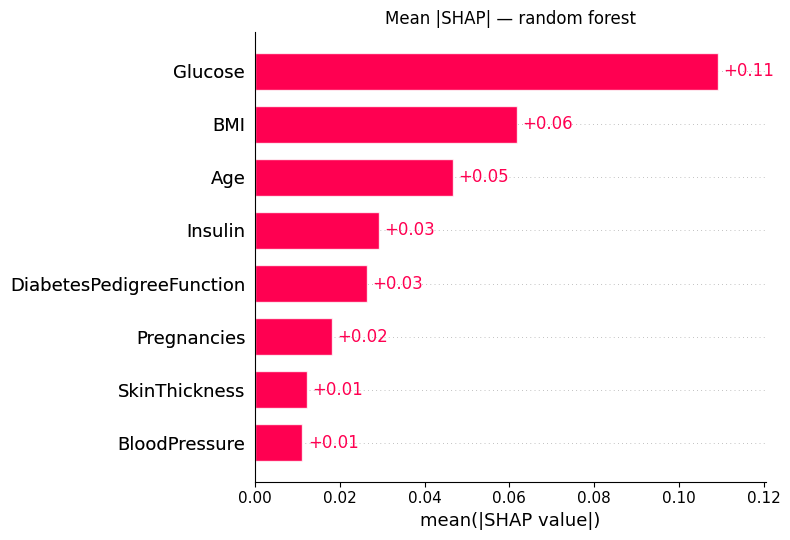

In [6]:
# ตามไม่ทัน? uncomment บรรทัดล่างแล้วรัน
# sv, X_test_imp = load_checkpoint("lab3-2")

shap.plots.bar(sv, show=False)
plt.title("Mean |SHAP| — random forest"); plt.tight_layout(); plt.show()

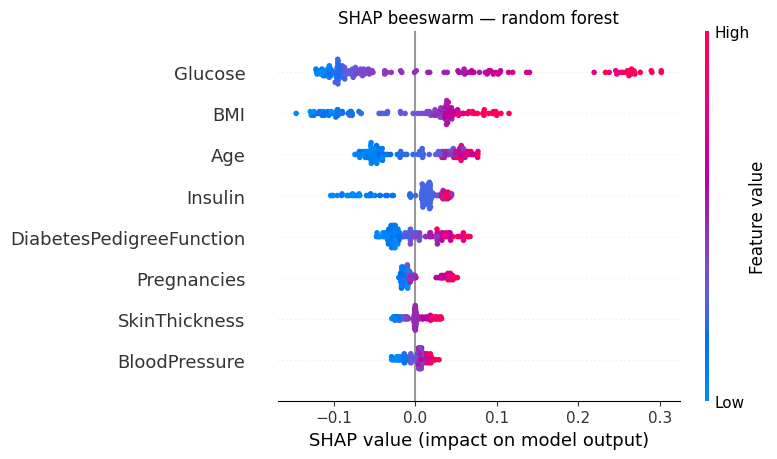

In [7]:
# ✔ TODO 3.2: วาด beeswarm ด้วย shap.plots.beeswarm(sv, show=False)
shap.plots.beeswarm(sv, show=False)
plt.title("SHAP beeswarm — random forest"); plt.tight_layout(); plt.show()

**อ่าน beeswarm:**
- `Glucose` อยู่บนสุด: จุดแดง (น้ำตาลสูง) อยู่ฝั่งบวกไกล → ดันความเสี่ยงขึ้นแรงที่สุด
- `BMI`, `Age` รองลงมาในทิศเดียวกัน
- feature ด้านล่าง (`BloodPressure`, `SkinThickness`) ส่งผลน้อยมาก

**คำถาม:** สิ่งที่ model เรียนรู้ ตรงกับความรู้ทางการแพทย์ไหม? ถ้าไม่ตรง (เช่น feature แปลก ๆ ขึ้นมาบนสุด) อาจเป็นสัญญาณของ data leakage หรือ bias ในข้อมูล

## 3.3 Dependence: ความเสี่ยงเปลี่ยนตามค่า feature อย่างไร

scatter ของค่า `Glucose` (แกน x) กับ SHAP ของ `Glucose` (แกน y) — ใส่สีตาม feature อื่นเพื่อดู interaction

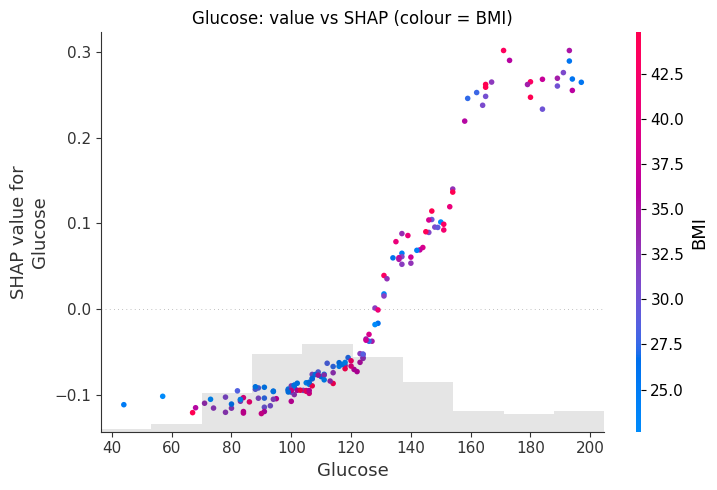

In [8]:
# ✔ TODO 3.3: วาด shap.plots.scatter(sv[:, "Glucose"], color=sv[:, "BMI"], show=False)
shap.plots.scatter(sv[:, "Glucose"], color=sv[:, "BMI"], show=False)
plt.title("Glucose: value vs SHAP (colour = BMI)"); plt.tight_layout(); plt.show()

**สังเกต:** ไม่เป็นเส้นตรง — ต่ำกว่า ~120 mg/dL SHAP ติดลบและขยับขึ้นช้า ๆ แล้ว **ขึ้นชัน** ช่วง ~125–160 (ใกล้เกณฑ์ OGTT ทางคลินิก) จากนั้น **อิ่มตัว**
Random Forest จับ "ขั้นบันได" แบบนี้ได้เอง ส่วน logistic regression บังคับให้เป็นเส้นตรงใน log-odds

## 3.4 Local: คนนี้เสี่ยงเพราะอะไร

**waterfall plot** เริ่มจาก base value (ค่าเฉลี่ย) แล้วบวก/ลบทีละ feature จนถึงความน่าจะเป็นของคนนี้
— นี่คือภาพที่เราจะใส่ใน app ให้ผู้ใช้เห็น

คนที่เสี่ยงสูงสุดใน test: แถวที่ 111, p = 0.77


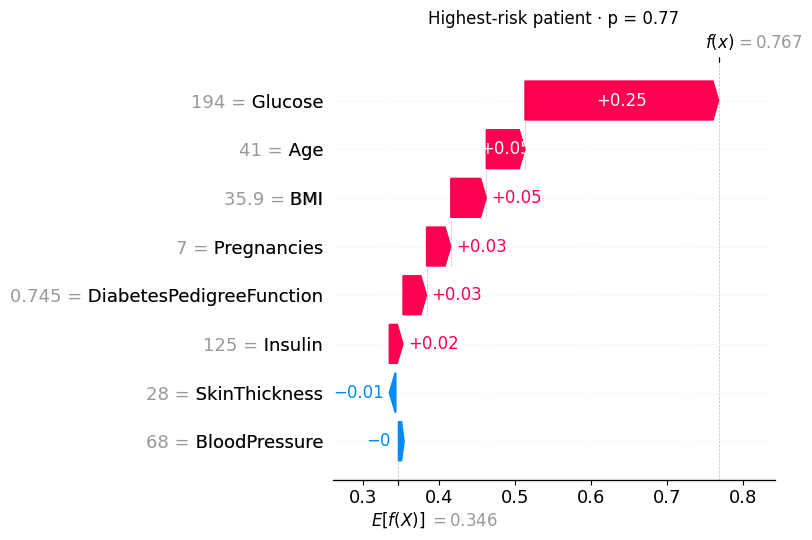

In [9]:
order = np.argsort(proba)
high, low = order[-1], order[0]
print(f"คนที่เสี่ยงสูงสุดใน test: แถวที่ {high}, p = {proba[high]:.2f}")
shap.plots.waterfall(sv[high], show=False)
plt.title(f"Highest-risk patient · p = {proba[high]:.2f}"); plt.tight_layout(); plt.show()

ค่าทางซ้าย (เช่น `194 = Glucose`) คือค่าจริงของคนนี้ **หลังเติม missing** — ถ้าคนนี้ไม่มีค่า `Insulin` จะเห็นเป็น median ของ train

ลองหา **คนที่ model ตัดสินใกล้เส้น threshold** (ยากที่สุด) แล้วดูว่าอะไรทำให้ก้ำกึ่ง

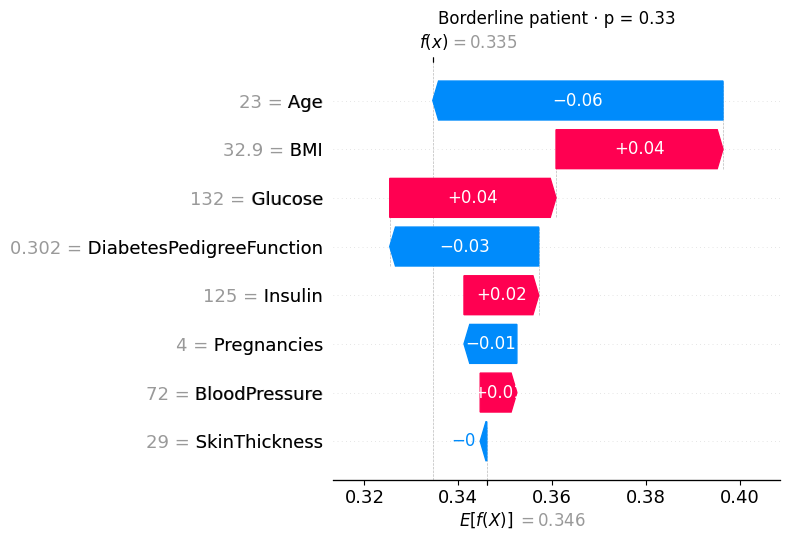

ผลจริงของคนนี้: เป็นเบาหวาน


In [10]:
THRESHOLD = 0.33   # threshold จาก Lab 2 (recall ≥ 0.80)

# ✔ TODO 3.4: หา index ของคนที่ proba ใกล้ THRESHOLD ที่สุด (hint: np.argmin(np.abs(proba - THRESHOLD))) แล้ววาด waterfall
borderline = np.argmin(np.abs(proba - THRESHOLD))
shap.plots.waterfall(sv[borderline], show=False)
plt.title(f"Borderline patient · p = {proba[borderline]:.2f}"); plt.tight_layout(); plt.show()
print("ผลจริงของคนนี้:", "เป็นเบาหวาน" if y_test.iloc[borderline] == 1 else "ไม่เป็น")

In [11]:
show_check(abs(proba[borderline] - THRESHOLD) < 0.03, f"คนก้ำกึ่ง: p = {proba[borderline]:.3f}", "ยังไม่ได้คนที่ใกล้ threshold")

✅ คนก้ำกึ่ง: p = 0.335


## 3.5 เทียบกับ Logistic regression

สำหรับ linear model ใช้ `shap.LinearExplainer` — SHAP ของ feature $j$ คือ $b_j (x_j - \bar{x}_j)$ (ใน **log-odds**)
ต้องส่งข้อมูลที่ผ่าน imputer + scaler แล้ว (`logreg[:-1].transform`) และข้อมูล train เป็น background

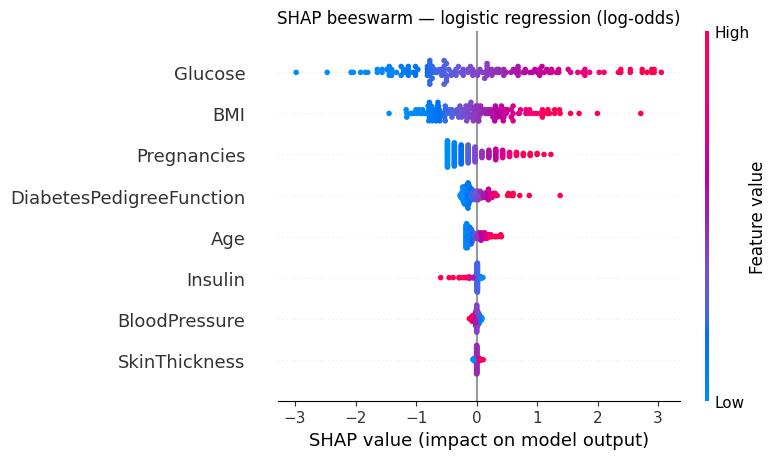

In [12]:
Xtr_lr = pd.DataFrame(logreg[:-1].transform(X_train), columns=FEATURES)
Xte_lr = pd.DataFrame(logreg[:-1].transform(X_test), columns=FEATURES, index=X_test.index)

lin_explainer = shap.LinearExplainer(logreg[-1], Xtr_lr)
sv_lr = lin_explainer(Xte_lr)

shap.plots.beeswarm(sv_lr, show=False)
plt.title("SHAP beeswarm — logistic regression (log-odds)"); plt.tight_layout(); plt.show()

In [13]:
rank = pd.DataFrame({
    "random forest": pd.Series(np.abs(sv.values).mean(0), index=FEATURES).rank(ascending=False),
    "logistic regression": pd.Series(np.abs(sv_lr.values).mean(0), index=FEATURES).rank(ascending=False),
}).astype(int).sort_values("random forest")
rank

,random forest,logistic regression
Glucose,1,1
BMI,2,2
Age,3,5
Insulin,4,6
DiabetesPedigreeFunction,5,4
Pregnancies,6,3
SkinThickness,7,8
BloodPressure,8,7


สอง model ที่ต่างกันมากเห็นตรงกันว่า **Glucose → BMI** สำคัญที่สุด → เพิ่มความมั่นใจว่าเป็นสัญญาณจริงในข้อมูล

ใน linear model ทุกจุดของ feature หนึ่งเรียงเป็นเส้นตรงเดียวกัน (beeswarm ไล่สีเรียบ) ส่วน Random Forest กระจายมากกว่าเพราะมี interaction

## 3.6 SHAP ไม่ได้บอกอะไร (สำคัญมาก)

1. **SHAP อธิบาย model ไม่ใช่ธรรมชาติ** — "BMI ดันความเสี่ยงขึ้น" แปลว่า *model ใช้ BMI แบบนั้น* ไม่ได้พิสูจน์ว่าลด BMI แล้วจะลดความเสี่ยง (นั่นคือ causal inference)
2. **feature ที่ correlate กันแบ่งเครดิตกัน** — `Glucose` กับ `Insulin` สัมพันธ์กัน เครดิตอาจไหลไปตัวใดตัวหนึ่ง
3. **missing ที่ถูกเติม** — คนที่ไม่มีค่า `Insulin` ถูกเติมด้วย median; SHAP อธิบายค่าที่เติม ไม่ใช่ค่าจริง
4. **model ผิด คำอธิบายก็ผิด** — SHAP ทำให้ model โปร่งใส แต่ไม่ได้ทำให้ model ถูก

**แบบฝึก (ถ้ามีเวลา):** ใช้ `shap.plots.scatter` ดู `Age` — ความเสี่ยงเพิ่มตลอดหรือมีจุดอิ่มตัว? และลอง `shap.plots.waterfall` กับคนที่ model **ทำนายผิด** (FN)

**สรุป Lab 3**

- SHAP แยกการทำนายเป็น base value + เครดิตของแต่ละ feature (บวกกันได้พอดี)
- global: bar / beeswarm · dependence: scatter · local: waterfall
- ใช้ตรวจว่า model สมเหตุสมผล และสื่อสารเหตุผลให้ผู้ใช้ — แต่ไม่ใช่หลักฐานเชิงเหตุผล

ต่อไป Lab 4: ห่อ model + SHAP waterfall เป็น **web app** แล้ว deploy บน **Render**

In [14]:
save_checkpoint("lab3-end", sv=sv, sv_lr=sv_lr, X_test_imp=X_test_imp)